In [13]:
import os
import numpy as np
from PIL import Image
 
TRAIN_DIR = "/kaggle/input/datasets/salader/dogsvscats/train"
IMG_SIZE = (512, 512)
SAMPLE_SIZE = 200  # per class
 
def load_images(folder, label, n):
    files = os.listdir(folder)[:n]
    data, labels = [], []
    for fname in files:
        img = Image.open(os.path.join(folder, fname)).convert("RGB").resize(IMG_SIZE)
        data.append(np.array(img)); labels.append(label)
    return data, labels
 
cat_imgs, cat_labels = load_images(os.path.join(TRAIN_DIR, "cats"), "cat", SAMPLE_SIZE)
dog_imgs, dog_labels = load_images(os.path.join(TRAIN_DIR, "dogs"), "dog", SAMPLE_SIZE)
images = np.array(cat_imgs + dog_imgs)
true_labels = cat_labels + dog_labels
print(images.shape)



(400, 512, 512, 3)


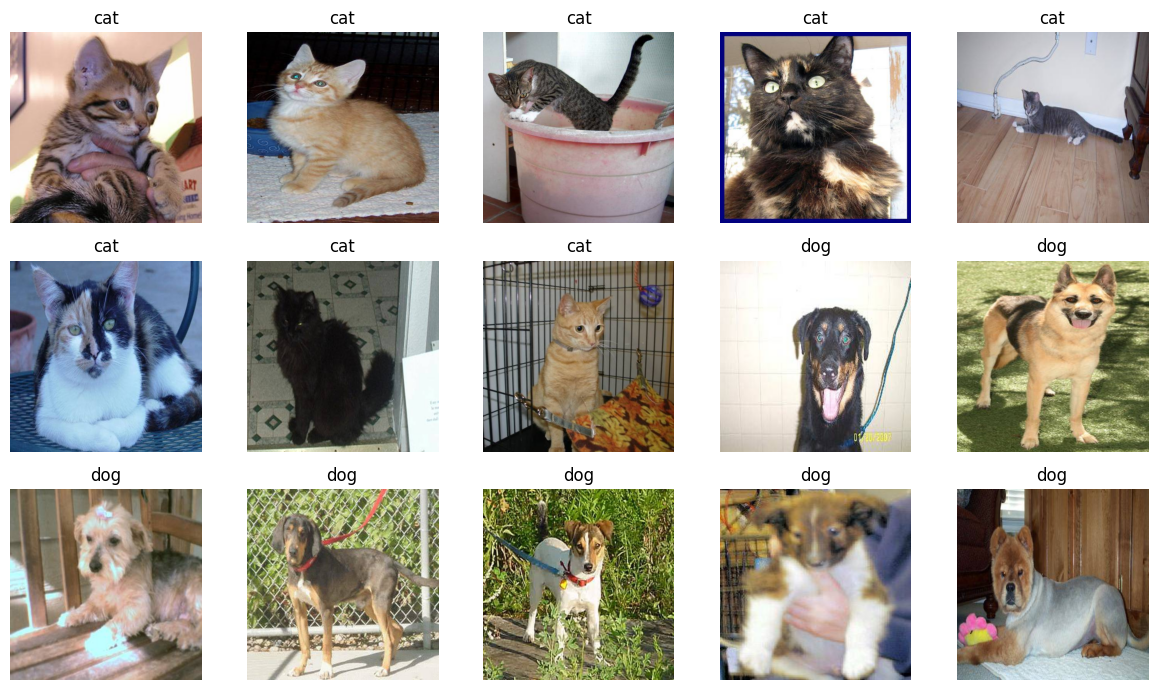

In [19]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 5, figsize=(12, 7))

for i in range(15):
    axes.flat[i].imshow(images[i * 25])
    axes.flat[i].set_title(true_labels[i * 25])
    axes.flat[i].axis("off")

plt.tight_layout()
plt.show()

In [4]:
X = images.reshape(len(images), -1) / 255.0
print(X.shape)


(400, 3072)


In [5]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X)


KMeans(n_clusters=2, n_init=10, random_state=42)

In [6]:
predicted_clusters = kmeans.predict(X)
import pandas as pd
print(pd.Series(predicted_clusters).value_counts())


0    206
1    194
Name: count, dtype: int64


In [7]:
comparison = pd.crosstab(predicted_clusters, true_labels)
print(comparison)


col_0  cat  dog
row_0          
0      107   99
1       93  101


In [11]:
from sklearn.metrics import accuracy_score

accuracy_1 = accuracy_score([1 if label == "dog" else 0 for label in true_labels],predicted_clusters)

accuracy_2 = accuracy_score([1 if label == "dog" else 0 for label in true_labels], 1 - predicted_clusters)

accuracy = max(accuracy_1, accuracy_2)

print(f"Clustering Accuracy: {accuracy:.3f}")

Clustering Accuracy: 0.520
